# Spoken Grammar Scoring Engine
**SHL Hiring Assessment 2026 · Anuj Dev Singh**

**Task.** Given a 45–60 s recording of someone speaking English, predict the grammar score (0–5, steps of 0.5)
that a human rater gave using SHL's rubric. 769 scored training clips, 216 test clips. Metrics: RMSE and Pearson.

**Approach in one paragraph.** A rater *hears* the speech, so the engine scores the audio directly and uses the
transcript as a second view. Five branches each predict a score:
1. **Frozen encoders + Ridge:** Whisper-large-v3 and WavLM-large turn each clip into one vector.
2. **Fine-tuned WavLM-large.**
3. **Fine-tuned audio LLM:** Qwen2-Audio-7B with QLoRA and a regression head.
4. **Adapter grader:** small adapters and one Transformer layer on frozen Whisper frames, trained with
   leakage-free pseudo-labels.
5. **Transcript features:** fluency and grammar measures from Whisper transcripts.

A non-negative linear stack, fitted on out-of-fold predictions, combines them. The test set contains no invalid
recordings, so the models learn from scores 1–5, and a simple rule keeps invalid-looking clips near 0.

**Two final submissions** (Kaggle allows two):
- **e013:** all five branches. Best cross-validation.
- **e009:** branches 1, 2, 3 and 5, without the adapter. Best public leaderboard score.

Section 4 explains why both are kept. Every number below comes from the same fixed cross-validation folds.

**Contents.** 1 Data · 2 Preprocessing · 3 Branches and stack · 4 Results (training RMSE, CV RMSE, Pearson)
· 5 Visualisations · 6 CV vs leaderboard · 7 Error analysis, limitations, what failed · 8 Reproduce

*Note: the competition data is for competition use only. This notebook shows aggregate numbers and plots only.
It never prints audio, transcripts or per-file rows.*

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from cv import DATA, get_folds, pearson, rmse  # noqa: E402

CACHE = ROOT / "cache"
FINAL, ALT = "e013", "e009"  # the two final submissions, written by src/final.py
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, ORANGE, GREY, GREEN = "#2f6db5", "#e07b39", "#8c8c8c", "#3a9a5b"

## 1. Data
- **Labels are skewed toward higher scores.**
- **37 clips are scored 0,** below the rubric's 1. A check with Whisper showed these are invalid recordings: high
  no-speech probability, low ASR confidence, often not confidently English.
- **The test set has none of them.** No test clip looks invalid to a detector that catches all 37 in train.
- **Test clips are shorter** (median 45 s vs 60 s) and slightly quieter.
- **The test recordings also differ in other ways:** a classifier tells train from test clips with AUC 0.84
  (section 6).

train clips 769, test clips 216
label mean 3.313, std 1.238, clips labelled 0: 37


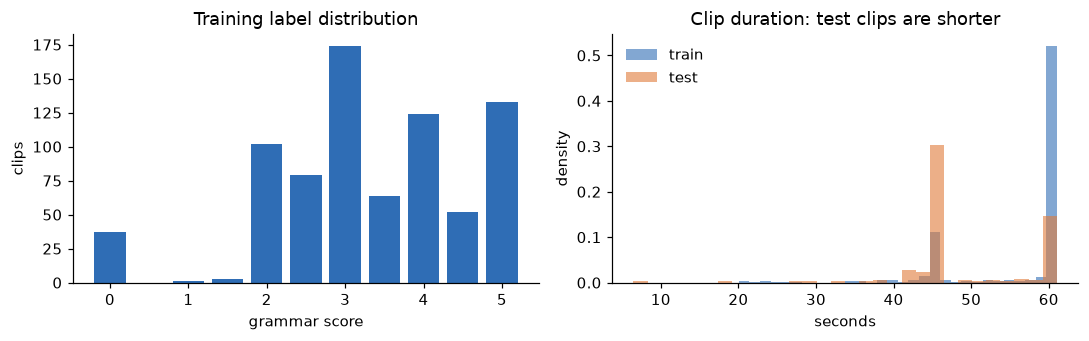

In [2]:
train = pd.read_csv(DATA / "train.csv")
audit = pd.read_csv(CACHE / "audit_audio.csv")
y_all = train.label
print(f"train clips {len(train)}, test clips {len(pd.read_csv(DATA / 'test.csv'))}")
print(f"label mean {y_all.mean():.3f}, std {y_all.std(ddof=0):.3f}, clips labelled 0: {(y_all == 0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
vc = y_all.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, width=0.4, color=BLUE)
ax[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
for s, c in [("train", BLUE), ("test", ORANGE)]:
    ax[1].hist(audit[audit.split == s].duration, bins=30, alpha=0.6, color=c, label=s, density=True)
ax[1].set(title="Clip duration: test clips are shorter", xlabel="seconds", ylabel="density")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. Preprocessing
- **No resampling needed.** All files are already 16 kHz mono 16-bit, with no clipping and no duplicate files.
- **Loudness (RMS) normalisation** to about −20 dBFS, so quiet test clips match train. RMS rather than peak, so
  one click cannot set the scale.
- **No silence trimming.** Pauses and hesitations are part of what raters hear.
- **30 s windows.** Whisper's encoder reads at most 30 s, so clips are cut into 30 s windows. For the frozen
  vectors, the pooled windows are averaged, weighted by length, and padding frames are ignored.
- **Length-free transcript features.** Every count is per second or per word, and raw duration and word counts
  are excluded, because test clips are shorter.

## 3. Branches and stack
| Branch | What it captures | Model |
|---|---|---|
| **Frozen audio** | Whisper-large-v3 encoder + WavLM-large: mean and std over time of every layer, averaged per model | Standardise → RidgeCV |
| **Fine-tuned WavLM** | WavLM-large trained end to end on the scores: 20 s random crops, 8 fixed epochs, learned layer weights + small MLP head | 5 fold models |
| **Fine-tuned audio LLM** | Qwen2-Audio-7B in 4-bit, LoRA rank 16 on the language model, plus a regression head reading the last prompt token. Rubric prompt + 30 s audio; 3 fixed epochs | 5 fold models |
| **Adapter grader** (e013 only) | Frozen Whisper-large-v3 frames from layers 16/22/27/32, every 80 ms. Per-layer adapters (LayerNorm → Linear 1280→128 → GELU → Linear), one Transformer layer, mean + std pooling, MLP head. About 1M trainable parameters. 20 s crops + masked spans, 15 fixed epochs, 3 seeds. Also learns from pseudo-labels (below) | 5 fold models × 3 seeds |
| **Transcript** | faster-whisper large-v3 transcripts, prompted to keep "um" and restarts. 42 features: pauses, speech rate, fillers, ASR confidence, vocabulary variety, LanguageTool errors per 100 words, GPT-2 likelihood, syntax depth, clauses | Standardise → RidgeCV |
| **Stack** | how much to trust each branch | Non-negative linear regression on out-of-fold predictions, then clipped to [0, 5] |

**Why an adapter grader?**
- The frozen Ridge branch averages over time *before* learning anything, so a short event such as a broken
  sentence is averaged away.
- The adapter learns from frame-level features first and pools afterwards.
- This was the best single model of the winning Speak & Improve 2025 system, and it is also our best single model.

**Pseudo-labels without leakage.** For fold k, a "teacher" built only from models that never saw fold k's labels
scores fold k's clips and the 216 test clips. The adapter then trains on the real labels of the other folds,
plus these pseudo-labels at half weight, and is scored on fold k's *real* labels. This lets it learn from
recordings like the test ones without leaking any label into its own validation score.

**Scores 1–5 plus an invalid-audio rule** (e013):
- Ridge models and the stack train on the 732 clips scored 1–5, because the test set has no invalid clips.
- One frozen model trained on *all* clips acts as a detector. If it predicts below 1.0, that low score is kept.
- In cross-validation this rule catches all 37 label-0 clips and no test clip.

**Validation:**
- Stratified 5-fold CV, with folds fixed once and reused for every model.
- Fine-tuning ran on repeat 0 only (one fine-tuned model costs 1–4 GPU-hours per fold), so every comparison uses
  repeat 0.
- The stack is itself cross-validated: its weights are fitted on 4 folds and scored on the 5th.
- **Decision rule for adding anything:** better on at least 4 of 5 folds, and a bootstrap 95% interval of the
  gain above 0.

Example of what the transcript features measure, on a **made-up** sentence (not competition data):

In [3]:
import spacy  # noqa: E402

nlp = spacy.load("en_core_web_md")
doc = nlp("Yesterday he go to the market and, um, I buyed a apple because it was cheap.")
print("tokens:", [t.text for t in doc])
print("he + base-form verb (agreement error):",
      [(t.text, t.head.text) for t in doc if t.lower_ == "he" and t.dep_ == "nsubj" and t.head.tag_ == "VBP"])
print("'a' before a vowel sound:", [(a.text, b.text) for a, b in zip(doc[:-1], doc[1:]) if a.lower_ == "a" and b.text[0] in "aeiou"])
print("subordinate clauses:", [t.text for t in doc if t.dep_ in {"advcl", "ccomp", "relcl", "mark"}])

tokens: ['Yesterday', 'he', 'go', 'to', 'the', 'market', 'and', ',', 'um', ',', 'I', 'buyed', 'a', 'apple', 'because', 'it', 'was', 'cheap', '.']
he + base-form verb (agreement error): [('he', 'go')]
'a' before a vowel sound: [('a', 'apple')]
subordinate clauses: ['because', 'was']


## 4. Results
- **Training RMSE (in-sample):** every refittable model (Ridge branches, stack) is refit on all 769 clips and
  scored on those same clips. It is optimistic by design.
- **CV RMSE / Pearson:** each clip is predicted by a model that never saw it. This is the honest estimate.
- **Fine-tuned and adapter branches have no all-data model.** Their test prediction averages the 5 fold models.
  So inside the stack's training RMSE, their out-of-fold predictions are used.
  - In e013 the adapter carries most of the stack weight, so its "in-sample" figure is close to its CV figure.
    That is expected, not a leak.

Base-model rows are scored on the 732 clips rated 1–5, which is what the test set looks like. The stack row
also shows all 769 clips.

In [4]:
def results(exp):
    d = np.load(CACHE / f"final_{exp}.npz", allow_pickle=True)
    s = json.load(open(CACHE / f"final_{exp}.json"))
    t = pd.read_csv(CACHE / f"final_{exp}_table.csv").set_index("model")
    y, P, st, nz = d["y"], d["P"], d["stack_oof"], d["y"] > 0
    rows = [dict(model=n, weight=round(s["weights"][n], 3), cv_rmse_1to5=rmse(y[nz], P[nz, i]),
                 cv_pearson_1to5=pearson(y[nz], P[nz, i]), train_rmse=t.loc[n, "train_rmse"])
            for i, n in enumerate(d["names"])]
    rows.append(dict(model="STACK", weight=np.nan, cv_rmse_1to5=rmse(y[nz], st[nz]), cv_pearson_1to5=pearson(y[nz], st[nz]),
                     train_rmse=s["train_rmse"]))
    out = pd.DataFrame(rows).rename(columns={"weight": "stack weight", "cv_rmse_1to5": "CV RMSE (1-5)",
                                             "cv_pearson_1to5": "CV Pearson (1-5)",
                                             "train_rmse": "Training RMSE (in-sample, all clips)"})
    print(f"== {exp} ==")
    print(out.round(4).to_string(index=False))
    print(f"STACK on all 769 clips: training RMSE (in-sample) {s['train_rmse']:.4f} | CV RMSE {s['cv_rmse']:.4f} | "
          f"CV Pearson {s['cv_pearson']:.4f}")
    print("per-fold CV RMSE (all clips):", np.round(s["fold_rmse"], 4))
    print(f"mean baseline (predict the train mean): RMSE {rmse(y, np.full_like(y, y.mean())):.4f}, Pearson 0\n")
    return d


d13, d09 = results(FINAL), results(ALT)

== e013 ==
           model  stack weight  CV RMSE (1-5)  CV Pearson (1-5)  Training RMSE (in-sample, all clips)
          frozen         0.081         0.5293            0.8529                                0.4407
       finetuned         0.021         0.5498            0.8435                                   NaN
        audiollm         0.085         0.6017            0.8070                                   NaN
   adapter_wavlm         0.000         0.5371            0.8504                                   NaN
adapter3_whisper         0.767         0.4808            0.8807                                   NaN
            text         0.080         0.7633            0.6605                                0.8666
           STACK           NaN         0.4792            0.8812                                0.4426
STACK on all 769 clips: training RMSE (in-sample) 0.4426 | CV RMSE 0.4699 | CV Pearson 0.9253
per-fold CV RMSE (all clips): [0.4294 0.5131 0.4734 0.445  0.484 ]
mean baselin

**Summary of the two final submissions:**

| | Training RMSE (in-sample) | CV RMSE (all clips) | CV Pearson (all clips) | CV RMSE (1–5 clips) | Public LB RMSE |
|---|---|---|---|---|---|
| Mean baseline | 1.238 | 1.238 | 0.000 | – | 1.0050 |
| **e009** (no adapter) | 0.370 | 0.492 | 0.918 | 0.501 | **0.3655** |
| **e013** (with adapter) | 0.443 | **0.470** | **0.925** | **0.479** | 0.3757 |

e013 is better than e009 on all 5 CV folds. e009 is better on the public leaderboard. Section 6 explains why
both are kept.

## 5. Visualisations

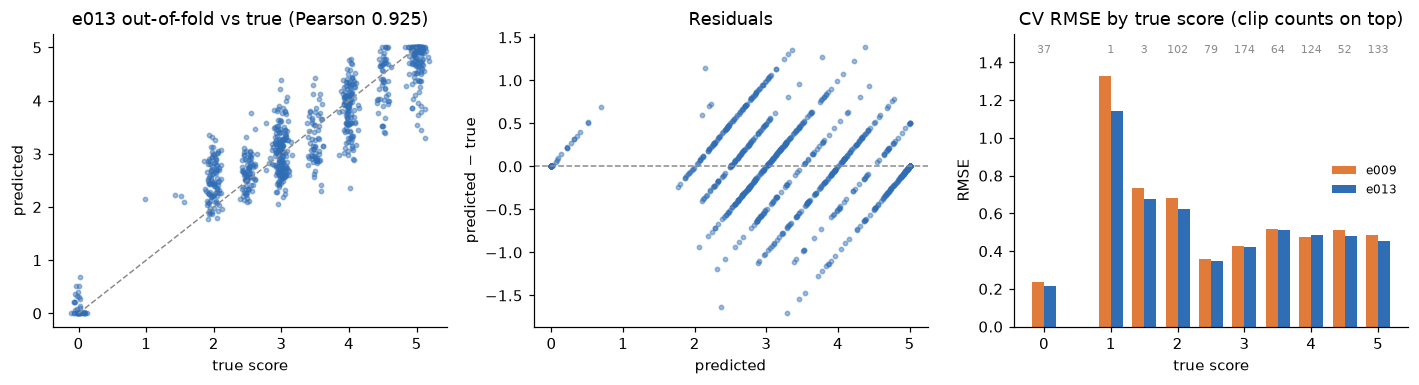

In [5]:
y, st = d13["y"], d13["stack_oof"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
jit = np.random.default_rng(0).normal(0, 0.06, len(y))
ax[0].scatter(y + jit, st, s=8, alpha=0.45, color=BLUE)
ax[0].plot([0, 5], [0, 5], color=GREY, lw=1, ls="--")
ax[0].set(title=f"e013 out-of-fold vs true (Pearson {pearson(y, st):.3f})", xlabel="true score", ylabel="predicted")
ax[1].scatter(st, st - y, s=8, alpha=0.45, color=BLUE)
ax[1].axhline(0, color=GREY, lw=1, ls="--")
ax[1].set(title="Residuals", xlabel="predicted", ylabel="predicted − true")
w = 0.18
for off, dd, c, lab in [(-w, d09, ORANGE, "e009"), (w, d13, BLUE, "e013")]:
    g = pd.DataFrame(dict(y=dd["y"], e2=(dd["stack_oof"] - dd["y"]) ** 2)).groupby("y")
    by = g.e2.mean().pow(0.5)
    ax[2].bar(by.index + off / 2, by.values, width=w, color=c, label=lab)
for xv, n in pd.Series(y).value_counts().sort_index().items():
    ax[2].text(xv, 1.45, str(n), ha="center", fontsize=7, color=GREY)
ax[2].set(title="CV RMSE by true score (clip counts on top)", xlabel="true score", ylabel="RMSE", ylim=(0, 1.55))
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**How the adapter improved, fold by fold** (RMSE on 1–5 clips; lower is better):
- The adapter beats the frozen Ridge it replaces as the main signal in every fold.
- Pseudo-labelling improves it again in every fold.

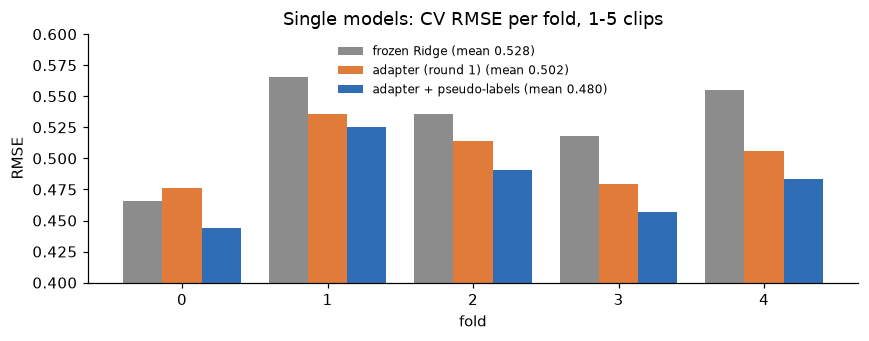

In [6]:
folds = get_folds()
nz13 = d13["y"] > 0
fold = d13["fold"]


def oof(name):
    o = pd.concat([pd.read_csv(CACHE / name / f"oof_fold{k}.csv") for k in range(5)]).set_index("filename")
    return o.loc[folds.filename, "pred"].to_numpy()


series = {"frozen Ridge": d13["P"][:, list(d13["names"]).index("frozen")],
          "adapter (round 1)": oof("adapter_whisper"), "adapter + pseudo-labels": oof("adapter3_whisper")}
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (lab, p) in enumerate(series.items()):
    r = [rmse(y[(fold == k) & nz13], p[(fold == k) & nz13]) for k in range(5)]
    ax.bar(np.arange(5) + (i - 1) * 0.27, r, width=0.27, label=f"{lab} (mean {np.mean(r):.3f})",
           color=[GREY, ORANGE, BLUE][i])
ax.set(title="Single models: CV RMSE per fold, 1-5 clips", xlabel="fold", ylabel="RMSE", ylim=(0.4, 0.6),
       xticks=range(5))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Which encoder layers matter?**
- For both encoders, averaging all layers beats any third of the layers alone.
- The early layers are the weakest, so the score depends on higher-level information about words and structure,
  not only on raw sound.
- Newer is not automatically better: frozen w2v-BERT 2.0 (2023, 4.5 M hours of pre-training) was the weakest
  encoder.

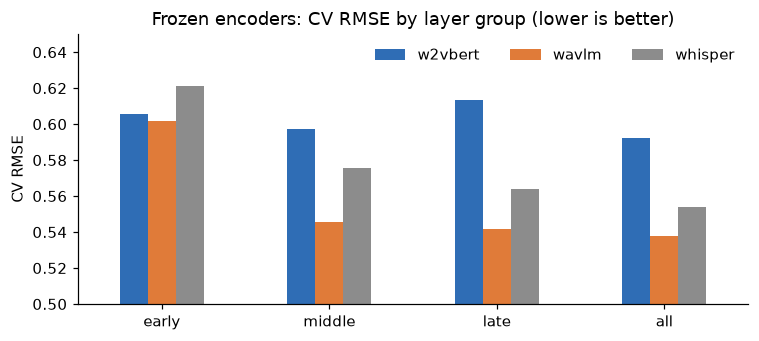

In [7]:
lg = pd.read_csv(CACHE / "e005_results.csv")
lg = lg[lg.layers != "concat"].copy()
lg["model"], lg["group"] = lg.features.str.split("_").str[0], lg.features.str.split("_").str[1]
piv = lg.pivot(index="group", columns="model", values="rmse").loc[["early", "middle", "late", "all"]]
ax = piv.plot.bar(figsize=(7, 3.2), color=[BLUE, ORANGE, GREY], rot=0)
ax.set(title="Frozen encoders: CV RMSE by layer group (lower is better)", ylabel="CV RMSE", xlabel="", ylim=(0.5, 0.65))
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

**Fine-tuning curves:** validation RMSE per epoch for each fold.
- The numbers of epochs (8 for WavLM, 3 for the audio LLM) were fixed in advance.
- No epoch was picked by looking at these curves, so the out-of-fold scores stay honest.

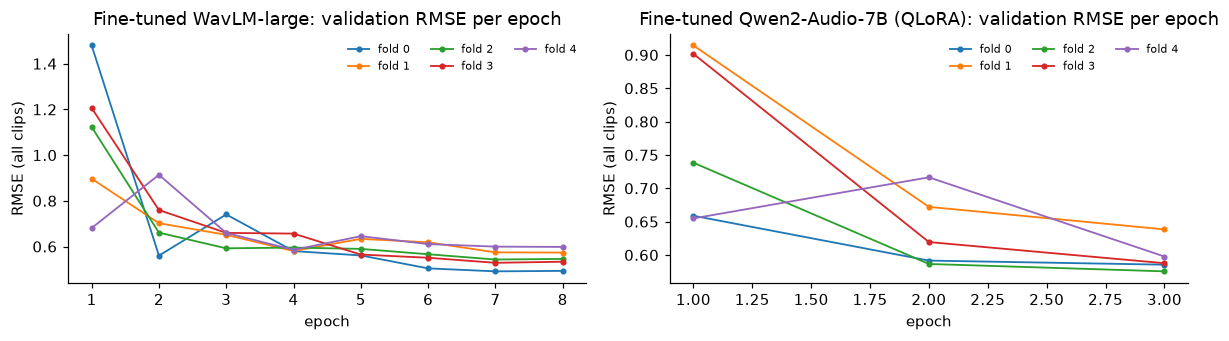

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, sub, title in [(ax[0], "ft", "Fine-tuned WavLM-large"), (ax[1], "alm", "Fine-tuned Qwen2-Audio-7B (QLoRA)")]:
    logs = pd.concat([pd.read_csv(CACHE / sub / f"log_fold{k}.csv") for k in range(5)])
    for k, gk in logs.groupby("fold"):
        a.plot(gk.epoch, gk.val_rmse, marker="o", ms=3, lw=1.2, label=f"fold {k}")
    a.set(title=f"{title}: validation RMSE per epoch", xlabel="epoch", ylabel="RMSE (all clips)")
    a.legend(frameon=False, ncol=3, fontsize=7)
plt.tight_layout()
plt.show()

**What the transcript features say:**
- The strongest single signals are Whisper's own **word confidence** and **vocabulary variety**.
- The direct grammar measures (LanguageTool error rate, GPT-2 likelihood, syntax) are weaker.
- Whisper rewrites disfluent, ungrammatical speech into clean text, so many errors never reach the transcript.
  This is why the audio branches carry most of the weight.

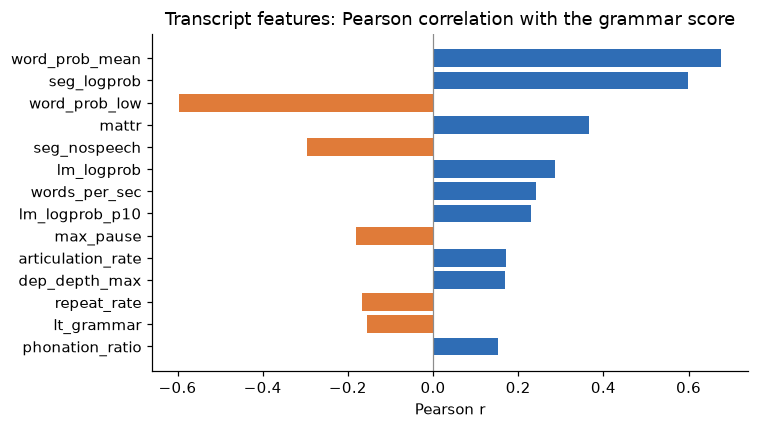

In [9]:
F = pd.read_parquet(CACHE / "feat_text.parquet")
F = F[F.split == "train"].merge(train, on="filename")
cols = [c for c in F.columns if c not in ("split", "filename", "label", "duration", "n_words", "n_sents")]
corr = pd.Series({c: np.corrcoef(F[c], F.label)[0, 1] for c in cols if F[c].std() > 0})
top = corr.reindex(corr.abs().sort_values().index[-14:])
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values])
ax.axvline(0, color=GREY, lw=0.8)
ax.set(title="Transcript features: Pearson correlation with the grammar score", xlabel="Pearson r")
plt.tight_layout()
plt.show()

## 6. CV vs leaderboard: why two final submissions
- **Up to e009, the public leaderboard moved in the same direction as CV every time.**
- **Every submission with the adapter grader was better in CV but worse on the public leaderboard:**
  e011 0.3742, e012 0.3790 and e013 0.3757, vs e009 0.3655.

  id                            what  CV RMSE (all clips)  public LB RMSE
e000                      train mean               1.2382          1.0050
e001            Whisper-tiny + Ridge               0.5679          0.4529
e002   Whisper-large + WavLM + Ridge               0.5237          0.4165
e006              + fine-tuned WavLM               0.5109          0.3985
e007           + transcript features               0.5003          0.3865
e009          + fine-tuned audio LLM               0.4916          0.3655
e011 + adapter grader (1-5 training)               0.4763          0.3742
e012                 adapter round 2               0.4739          0.3790
e013         adapter + pseudo-labels               0.4699          0.3757


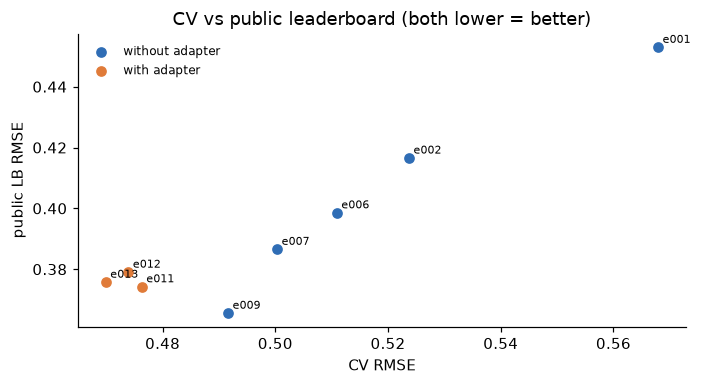

In [10]:
lb = pd.DataFrame([
    ("e000", "train mean", 1.2382, 1.0050), ("e001", "Whisper-tiny + Ridge", 0.5679, 0.4529),
    ("e002", "Whisper-large + WavLM + Ridge", 0.5237, 0.4165), ("e006", "+ fine-tuned WavLM", 0.5109, 0.3985),
    ("e007", "+ transcript features", 0.5003, 0.3865), ("e009", "+ fine-tuned audio LLM", 0.4916, 0.3655),
    ("e011", "+ adapter grader (1-5 training)", 0.4763, 0.3742), ("e012", "adapter round 2", 0.4739, 0.3790),
    ("e013", "adapter + pseudo-labels", 0.4699, 0.3757)], columns=["id", "what", "CV RMSE (all clips)", "public LB RMSE"])
print(lb.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
m = lb.id != "e000"
ad = lb.id.isin(["e011", "e012", "e013"])
ax.scatter(lb[m & ~ad]["CV RMSE (all clips)"], lb[m & ~ad]["public LB RMSE"], color=BLUE, label="without adapter")
ax.scatter(lb[ad]["CV RMSE (all clips)"], lb[ad]["public LB RMSE"], color=ORANGE, label="with adapter")
for _, r in lb[m].iterrows():
    ax.annotate(r.id, (r["CV RMSE (all clips)"], r["public LB RMSE"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(title="CV vs public leaderboard (both lower = better)", xlabel="CV RMSE", ylabel="public LB RMSE")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**What was checked, without using the leaderboard:**
- **Small public split.** The public score uses roughly a third of the 216 test clips. If e011 were truly
  better, a random subset that size would make it look this much worse 3–8% of the time. Unlikely, but possible.
- **Train/test shift is real.** A classifier separates train from test clips with AUC 0.84.
  - On the 25% of train clips that look most like test, e013 still beats e009 (0.501 vs 0.525).
  - Re-weighting training toward test-like clips did not help: only 49 of 732 clips carry real weight.
- **Disagreement test** (no labels needed): how far each model's predictions sit from the other models', on test
  vs on train.
  - The fine-tuned models behave the same on test as on train (ratios 0.90–0.95).
  - The adapters drift away on test (1.10–1.27).
  - So the adapter reacts to something in the test recordings that CV cannot see.
- **One targeted fix, judged by a rule set in advance:** per-clip normalisation of the encoder frames (classic
  cepstral mean/variance normalisation) removes each recording's constant microphone or room "colour".
  - It made CV worse on all 5 folds (0.492–0.494 vs 0.479) and on test-like clips.
  - It barely changed the drift (1.03–1.05 vs 1.07).
  - So it was not adopted.

**Decision:**
- Do not tune on the public leaderboard: it uses about 70 clips, while CV uses 769.
- Keep both views as the two final submissions:
  - **e013**, best on every CV check;
  - **e009**, best public score, and it does not use the adapter whose behaviour on test is less certain.

## 7. Error analysis, limitations, and what failed
- **Squeezing toward the middle.** Low scores are predicted too high and 5s too low (see "RMSE by true score").
  Scores 1.0–1.5 have only 4 training clips, so the model has almost no examples of the bottom of the scale.
- **Short clips are harder.** On train clips under 50 s, which are like most test clips, the error is higher
  (e013: 0.545 vs 0.456 on longer clips).
  - Training the adapter on variable-length crops with clip length as an input did not change that.
  - So short clips are not hard because of a length mismatch; they are probably harder recordings or speakers.
- **What ASR cannot see.** Whisper cleans up grammar errors, so transcript-based grammar features are weak. The
  audio branches do not have this problem, but they also respond to fluency and confidence, not grammar alone.
- **Small data.** About 585 training clips per fold. Fine-tuning a large model alone does *not* beat frozen
  features (fine-tuned WavLM 0.550 and audio LLM 0.597 vs frozen Ridge 0.521). They help as second opinions in
  the stack.

**Tried and dropped** (measured, kept for transparency; details in `docs/decisions.md`):

| Idea | Result |
|---|---|
| SVR instead of Ridge | 0.523 vs 0.524, no gain |
| Frozen w2v-BERT 2.0 added | 0.520 vs 0.524, within noise |
| Zero-shot Qwen2-Audio rubric judge | correlation with labels only 0.43; +0.0007 in the stack |
| WavLM adapter | weight 0 in the stack |
| Short-clip-aware adapter (round 2) | +0.002, bootstrap interval includes 0 |
| Importance-weighted stack | worse on test-like clips |
| Per-clip normalised adapter (round 4) | worse on all 5 folds |

## 8. Reproduce
```
python src/audit.py                       # data checks
python src/cv.py                          # fixed folds -> cache/folds.csv
# GPU stages on Kaggle T4 x2 (one worker per GPU); each builder writes kaggle/<stage>/, then:
#   kaggle kernels push -p kaggle/<stage> --accelerator NvidiaTeslaT4
#   kaggle kernels output <kernel> -p cache/<dir>
kaggle/build_embed.sh                     # frozen Whisper/WavLM embeddings -> cache/emb
kaggle/build_transcribe.sh                # transcripts -> cache/transcripts.jsonl
kaggle/build_finetune.sh                  # fine-tuned WavLM -> cache/ft
kaggle/build_ft_alm.sh                    # fine-tuned Qwen2-Audio -> cache/alm
kaggle/build_adapter.sh                   # adapter graders, round 1 -> cache/adapter_whisper, cache/adapter_wavlm
python src/features.py                    # transcript features (needs Java for LanguageTool)
python src/final.py --exp e011 --no-judge --nz --drop adapter2_whisper,adapter3_whisper,adapter4mean_whisper,adapter4meanvar_whisper
python src/pseudo.py                      # leakage-free pseudo-labels from the e011 teacher
kaggle/build_adapter3.sh                  # pseudo-labelled adapter -> cache/adapter3_whisper
# the two final submissions:
python src/final.py --exp e013 --no-judge --nz --drop adapter_whisper,adapter2_whisper,adapter4mean_whisper,adapter4meanvar_whisper
python src/final.py --exp e009 --no-judge --drop adapter_whisper,adapter_wavlm,adapter2_whisper,adapter3_whisper,adapter4mean_whisper,adapter4meanvar_whisper
```
- Both final commands were re-run from the cached branch outputs and reproduce the submitted files exactly.
- Heavy stages write checkpoints, so a dropped Kaggle session can resume.
- This notebook only reads the cached results in `cache/`.